# Project 1: Transactions – Pass 06



## Problem Definition



#### 1. State the business problem.

Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.  Mention which model will be used, if known.



> We want to predict whether or not a future customer will complete a transaction (e.g., a product purchase, loan or bill payment, or subscription retention) based on prior transaction data. Such predictions can help determine higher-risk customers and present incentives to drive future transaction completions and increase sales.

> This is a supervised, categorical binary classification problem, where the target data is whether a customer transaction was successful (true or false). To achieve this, it uses a Gaussian Naive Bayes model to make predictions about transaction success.




## Data Collection



#### 2. Load Pandas, Numpy, and Matplotlib modules

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

#### 3. Load data Train.csv from AWS S3.

In [2]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'

- Set number of columns and rows for this pass:

In [3]:
# set cols and rows for pass
num_cols = 15
num_rows = 10_000

num_cols, num_rows

(15, 10000)

- Read in the data from .csv using pandas:

In [4]:
# make dataframe
df = pd.read_csv(
    url,
    usecols=range(num_cols),
    nrows=num_rows,
)

- Check the dataframe:

In [5]:
# check dataframe
df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,train_9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,9996,train_9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,9997,train_9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,9998,train_9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Data Cleaning



#### 4. Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



In [6]:
# define target_col
target_col = 'target'
target_col

'target'

- head

In [7]:
# head
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.476,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- tail

In [8]:
# tail
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
9995,9995,train_9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,9996,train_9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,9997,train_9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,9998,train_9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,9999,train_9999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- shape

In [9]:
# shape
df.shape

(10000, 15)

- size

In [10]:
# size
df.size

150000

- info

In [11]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  10000 non-null  int64  
 1   ID_code     10000 non-null  object 
 2   target      1686 non-null   float64
 3   var_0       1686 non-null   float64
 4   var_1       1686 non-null   float64
 5   var_2       1686 non-null   float64
 6   var_3       0 non-null      float64
 7   var_4       1686 non-null   float64
 8   var_5       0 non-null      float64
 9   var_6       0 non-null      float64
 10  var_7       1686 non-null   float64
 11  var_8       1686 non-null   float64
 12  var_9       0 non-null      float64
 13  var_10      0 non-null      float64
 14  var_11      0 non-null      float64
dtypes: float64(13), int64(1), object(1)
memory usage: 1.1+ MB


- describe

In [12]:
# describe
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
count,10000.00000,1686.000000,1686.000000,1686.000000,1686.000000,0.0,1686.000000,0.0,0.0,1686.000000,1686.000000,0.0,0.0,0.0
mean,4999.50000,0.098458,7.493109,15.840630,12.667966,NaN,-0.461214,NaN,NaN,1.276329,6.812313,NaN,NaN,NaN
std,2886.89568,0.298021,3.090435,3.086651,4.187706,NaN,6.014515,NaN,NaN,5.103567,0.374905,NaN,NaN,NaN
min,0.00000,0.000000,-0.101600,7.700200,3.218700,NaN,-16.855000,NaN,NaN,-11.731000,5.688300,NaN,NaN,NaN
25%,2499.75000,0.000000,5.174825,13.739200,9.601600,NaN,-4.893675,NaN,NaN,-2.458950,6.559500,NaN,NaN,NaN
50%,4999.50000,0.000000,7.379350,15.992700,12.478250,NaN,-0.190200,NaN,NaN,1.080350,6.795350,NaN,NaN,NaN
75%,7499.25000,0.000000,9.708875,18.155675,15.725050,NaN,3.730575,NaN,NaN,5.107175,7.071325,NaN,NaN,NaN
max,9999.00000,1.000000,16.716500,23.971700,24.828500,NaN,15.973100,NaN,NaN,17.441800,7.877900,NaN,NaN,NaN


- nunique

In [13]:
# nunique
df.nunique()

,0
Unnamed: 0,10000
ID_code,10000
target,2
var_0,1677
var_1,1663
var_2,1672
var_3,0
var_4,1678
var_5,0
var_6,0


- unique

In [14]:
# unique
df[target_col].unique()

array([nan,  0.,  1.])

- isnull

In [15]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
var_3,10000
var_6,10000
var_11,10000
var_9,10000
var_10,10000
var_5,10000
var_0,8314
target,8314
var_4,8314
var_2,8314


In [16]:
# isnull frequencies
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
var_3,100.00
var_6,100.00
var_11,100.00
var_9,100.00
var_10,100.00
var_5,100.00
var_0,83.14
target,83.14
var_4,83.14
var_2,83.14


- dtypes

In [17]:
# dtypes
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,float64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64


In [18]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(118198)

#### 5. NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [19]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
target,
NaN,8314
0.0,1520
1.0,166


In [21]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
target,
NaN,83.14
0.0,15.20
1.0,1.66


In [22]:
# target col size/shape
df[[target_col]].shape[0]

10000

In [23]:
# sum of nulls in target
df[[target_col]].isnull().sum()

,0
target,8314


- Summary:

  - target column: 'target'
  - feature columns: 'var_0' - 'var_11'
  - identifier columns (likely): 'Unnamed', 'ID_code'
  - null columns: 6 [3, 6, 11, 9, 10, 5]
  - null rows (target): 8314

#### 6. If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


In [24]:
# head again to double-check
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.476,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
# 1. 'Unnamed' and 'ID_code are very likely identifier columns, and should be dropped; target and var_0 - var_11 will be kept
# 2. 8314 null target columns should be dropped
# 3. 6 null feature columns should be dropped
# 4. After this, drop rows for any column with low null count
# 5. Finally, impute remaining nulls with column medians

- backup 1

In [27]:
# make backup
df_bak = df.copy()
df_bak

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,train_9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,9996,train_9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,9997,train_9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,9998,train_9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
# restore from backup
df = df_bak.copy()
df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,train_9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,9996,train_9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,9997,train_9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,9998,train_9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
# keep the target and all features
df = df.drop( columns = ['Unnamed: 0', 'ID_code'] )

In [30]:
# check our dataframe (display transformed df)
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- backup 2

In [31]:
# backup 2
df_bak2 = df.copy()
df_bak2

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [43]:
# restore from backup 2
df = df_bak2.copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [44]:
# preview filtering rows for where target is null
df.loc[df[target_col].isnull() == False]

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,NaN,-4.5570,NaN,NaN,-2.0199,6.4613,NaN,NaN,NaN
9982,0.0,7.4992,12.3931,15.6143,NaN,3.9159,NaN,NaN,-6.4257,6.4960,NaN,NaN,NaN
9983,0.0,3.6195,11.1681,6.0020,NaN,2.7570,NaN,NaN,-1.3041,7.3073,NaN,NaN,NaN
9993,0.0,6.6722,17.1154,9.2696,NaN,8.2625,NaN,NaN,4.0066,6.6464,NaN,NaN,NaN


In [45]:
# execute the drop
df = df.loc[df[target_col].isnull() == False].copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,NaN,-4.5570,NaN,NaN,-2.0199,6.4613,NaN,NaN,NaN
9982,0.0,7.4992,12.3931,15.6143,NaN,3.9159,NaN,NaN,-6.4257,6.4960,NaN,NaN,NaN
9983,0.0,3.6195,11.1681,6.0020,NaN,2.7570,NaN,NaN,-1.3041,7.3073,NaN,NaN,NaN
9993,0.0,6.6722,17.1154,9.2696,NaN,8.2625,NaN,NaN,4.0066,6.6464,NaN,NaN,NaN


In [46]:
# backup 3
df_bak3 = df.copy()
df_bak3

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,NaN,-4.5570,NaN,NaN,-2.0199,6.4613,NaN,NaN,NaN
9982,0.0,7.4992,12.3931,15.6143,NaN,3.9159,NaN,NaN,-6.4257,6.4960,NaN,NaN,NaN
9983,0.0,3.6195,11.1681,6.0020,NaN,2.7570,NaN,NaN,-1.3041,7.3073,NaN,NaN,NaN
9993,0.0,6.6722,17.1154,9.2696,NaN,8.2625,NaN,NaN,4.0066,6.6464,NaN,NaN,NaN


In [47]:
# restore from backup
df = df_bak3.copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,NaN,-4.5570,NaN,NaN,-2.0199,6.4613,NaN,NaN,NaN
9982,0.0,7.4992,12.3931,15.6143,NaN,3.9159,NaN,NaN,-6.4257,6.4960,NaN,NaN,NaN
9983,0.0,3.6195,11.1681,6.0020,NaN,2.7570,NaN,NaN,-1.3041,7.3073,NaN,NaN,NaN
9993,0.0,6.6722,17.1154,9.2696,NaN,8.2625,NaN,NaN,4.0066,6.6464,NaN,NaN,NaN


In [48]:
# preview drop null columns
df.drop( columns = ['var_3', 'var_5', 'var_6', 'var_9', 'var_10', 'var_11'] )

,target,var_0,var_1,var_2,var_4,var_7,var_8
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,0.0,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,0.0,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,0.0,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


In [49]:
# drop columns
df = df.drop( columns = ['var_3', 'var_5', 'var_6', 'var_9', 'var_10', 'var_11'] )
df

,target,var_0,var_1,var_2,var_4,var_7,var_8
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,0.0,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,0.0,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,0.0,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


In [50]:
# make a backup
df_bak4 = df.copy()
df_bak4

,target,var_0,var_1,var_2,var_4,var_7,var_8
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,0.0,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,0.0,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,0.0,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


In [51]:
# restore from backup
df = df_bak4.copy()
df

,target,var_0,var_1,var_2,var_4,var_7,var_8
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,0.0,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,0.0,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,0.0,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


In [52]:
# look for nulls in new cleaned data frame
df.isnull().sum().sort_values( ascending = False )

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0


In [53]:
# No more null values, so we're done! ( skip numbers 4 and 5 from above :D )

## Exploratory Data Analysis

Produce some visual analysis of the data.  Recall that Gaussian Naive Bayes assumes the features are normally distributed and independent. Note: you might have to do multiple plots in groups.



#### 7. Check the distributions of all variables by plotting.

array([[<Axes: title={'center': 'target'}>,
        <Axes: title={'center': 'var_0'}>,
        <Axes: title={'center': 'var_1'}>],
       [<Axes: title={'center': 'var_2'}>,
        <Axes: title={'center': 'var_4'}>,
        <Axes: title={'center': 'var_7'}>],
       [<Axes: title={'center': 'var_8'}>, <Axes: >, <Axes: >]],
      dtype=object)

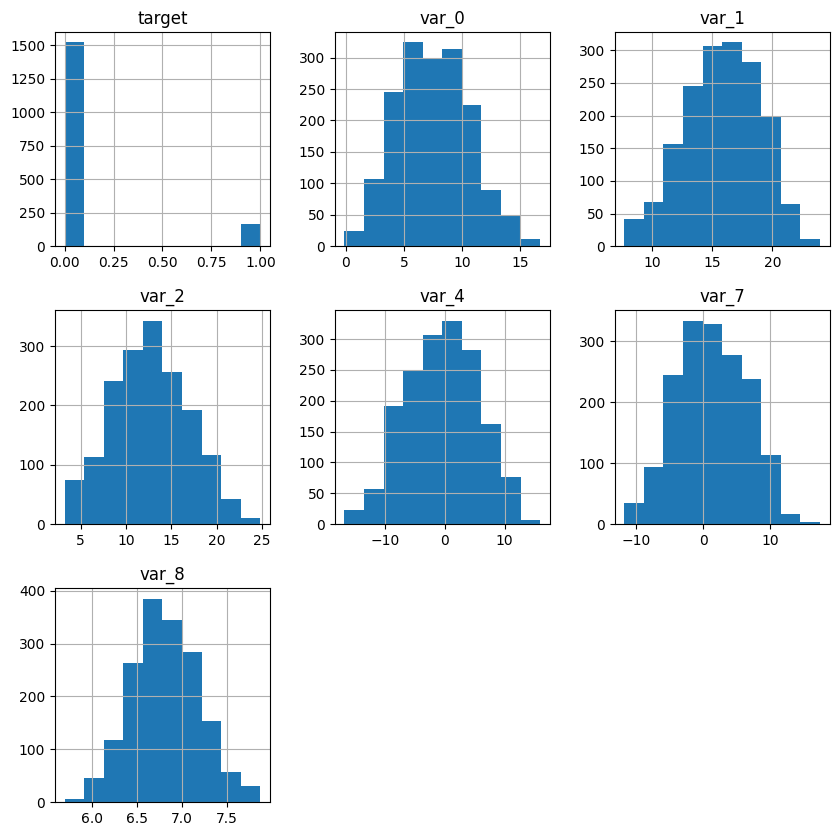

In [55]:
# Display a histogram
df.hist(figsize=(10, 10))

<Axes: >

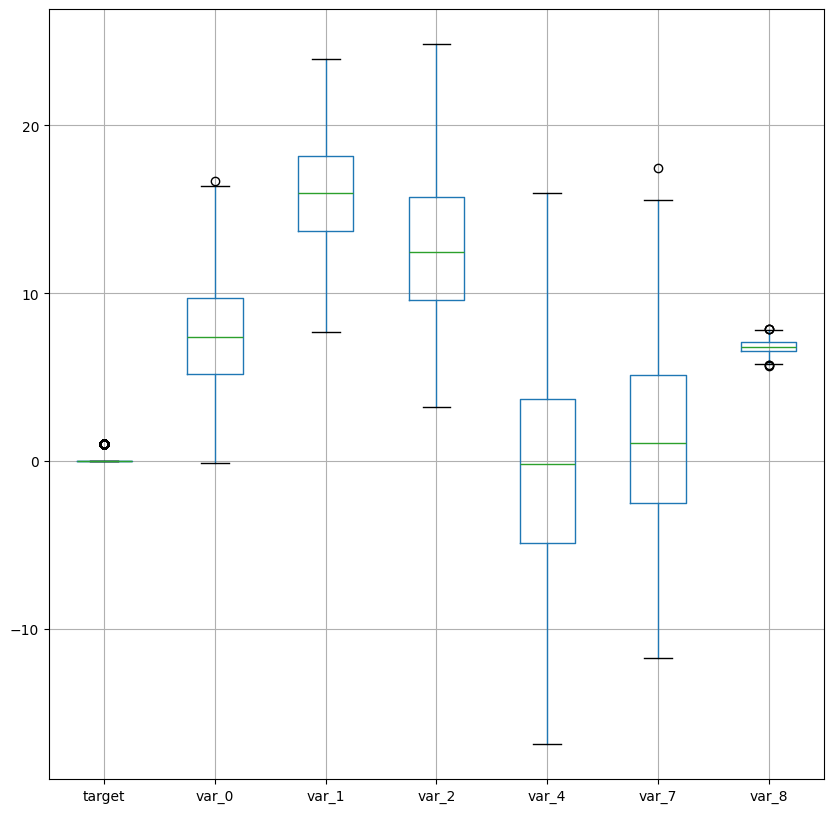

In [56]:
# display a boxplot
df.boxplot(figsize=(10, 10))

#### 8. Check the correlation values between all **feature columns** to ensure there are no substantial correlations between features. This is important to support the decision to classify the ‘target’ using Naïve Bayes.



In [57]:
# column correlations
column_correlations = df.corr()
column_correlations

,target,var_0,var_1,var_2,var_4,var_7,var_8
target,1.000000,0.037293,-0.026791,-0.041715,-0.038164,0.003941,0.021176
var_0,0.037293,1.000000,0.005254,-0.008940,-0.032564,0.019145,-0.004555
var_1,-0.026791,0.005254,1.000000,-0.006304,0.027493,0.033324,0.005790
var_2,-0.041715,-0.008940,-0.006304,1.000000,0.032350,0.015287,-0.007869
var_4,-0.038164,-0.032564,0.027493,0.032350,1.000000,0.016244,-0.016298
var_7,0.003941,0.019145,0.033324,0.015287,0.016244,1.000000,-0.031002
var_8,0.021176,-0.004555,0.005790,-0.007869,-0.016298,-0.031002,1.000000


<Axes: >

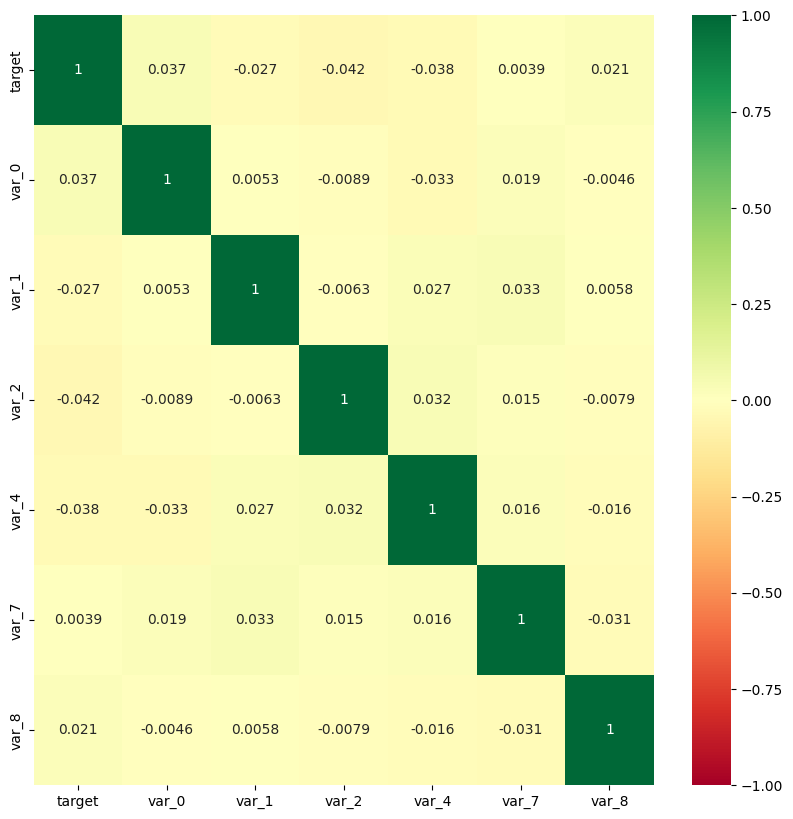

In [59]:
# Display correlation matrix
plt.figure(figsize = (10, 10))
sns.heatmap(
    column_correlations,
    annot = True,
    vmin = -1,
    vmax = 1,
    cmap = 'RdYlGn'
)

#### 9. Create two data frames: one with all successful transactions, one with all unsuccessful transactions. **Make sure they are copies and not slices**.




In [60]:
# make successful (copy)
df_successful   = df[ df[target_col] == 1 ].copy()
df_successful

,target,var_0,var_1,var_2,var_4,var_7,var_8
57,1.0,8.9078,12.1321,9.4707,-5.8102,0.4521,7.1264
125,1.0,6.2143,20.0990,23.5009,-0.8917,-3.9167,6.6863
151,1.0,8.9083,12.1117,18.0359,-4.9628,10.1135,6.8962
155,1.0,6.5612,13.9638,5.1980,12.1092,8.4874,6.4781
302,1.0,4.4616,9.7572,12.9317,7.6485,0.6382,5.8025
...,...,...,...,...,...,...,...
9704,1.0,3.8035,15.8842,9.7204,1.6659,9.4225,7.2885
9721,1.0,8.0545,13.9124,14.7748,-6.4229,9.2862,6.4995
9760,1.0,8.6481,15.4023,6.3946,-5.2774,8.7673,7.7839
9832,1.0,11.4846,18.8724,8.7859,-1.6645,3.9079,6.6286


In [61]:
# make unsuccessful (copy)
df_unsuccessful = df[ df[target_col] == 0 ].copy()
df_unsuccessful

,target,var_0,var_1,var_2,var_4,var_7,var_8
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,0.0,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,0.0,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,0.0,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


## Data Processing



### Single Cross-validation ( CV )



#### 10. Create two data sets: one with all the feature columns (everything except for Unnamed: 0, ID_code and target) and one with just the target. Make sure they are copies and not slices.  And make sure they are the correct dimensions.



In [62]:
# make target and features
target   = df[ target_col ].copy()
features = df.drop( columns = [target_col] ).copy()

In [63]:
# check target
target

,target
3,0.0
5,0.0
11,0.0
15,0.0
19,0.0
...,...
9978,0.0
9982,0.0
9983,0.0
9993,0.0


In [64]:
# check target value counts
target.value_counts()

,count
target,
0.0,1520
1.0,166


In [65]:
# check target dimensions and type
type(target), target.shape, target.ndim

(pandas.core.series.Series, (1686,), 1)

In [66]:
# check features
features

,var_0,var_1,var_2,var_4,var_7,var_8
3,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...
9978,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


In [67]:
# check features dimensions and type
type(features), features.shape, features.ndim

(pandas.core.frame.DataFrame, (1686, 6), 2)

#### 11. Define an empty Gaussian Naïve Bayes model using Sklearn.



In [68]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### 12. Divide the two data sets you created in step #10 into training and testing subsets, i.e. train-test split.



In [69]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split( features, target, test_size = 0.25 )

#### 13. Train ( fit ) the model using the training subset of the dataset.



In [70]:
# Train ( fit ) the model
modelGNB.fit(X_train, y_train)

GaussianNB()

#### 14. Test the model ( predict ) using the testing subset of the dataset.



In [71]:
# Make predictions using the model
y_pred = modelGNB.predict(X_test)

#### 15. Calculate and report the accuracy.



In [72]:
# Calculate the accuracy
accuracy = metrics.accuracy_score(y_test, y_pred)
accuracy

0.8909952606635071

#### 16. Present a confusion matrix and heatmap



Text(113.9222222222222, 0.5, 'Predicted')

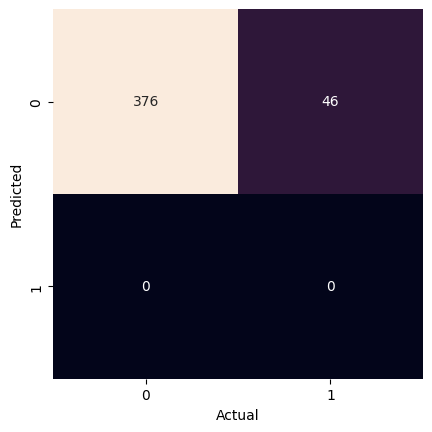

In [73]:
# Display confusion matrix
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')

#### 17. Present the results of a Classification Report (sklearn.metrics.classification_report).

In [75]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True, zero_division = 0)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0.0,0.890995,1.000000,0.942356,376.000000
1.0,0.000000,0.000000,0.000000,46.000000
accuracy,0.890995,0.890995,0.890995,0.890995
macro avg,0.445498,0.500000,0.471178,422.000000
weighted avg,0.793873,0.890995,0.839635,422.000000


In [76]:
# Save variable values
X_train_SCV = X_train
X_test_SCV  = X_test
y_train_SCV = y_train
y_test_SCV  = y_test
y_pred_SCV  = y_pred



### Multiple Cross-validation ( CV )



#### 18. Perform a cross-validation loop and record the accuracy of your model during each iteration.



In [ ]:
loop_count = 100

In [ ]:
# Multiple CV loop

# Create array to hold results (accuracies)
n = loop_count
accuracies = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( features, target, test_size = 0.25 )

  # Create an empty GNB model
  modelGNB = GaussianNB()

  # Train ( fit ) the model
  modelGNB.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = modelGNB.predict(X_test)

  # Calculate the accuracy and save to array
  accuracies[i] = metrics.accuracy_score(y_test, y_pred)

#### 19. Report the mean accuracy. How does it compare to the accuracy you calculated for the Single CV?



In [ ]:
# Calculate mean of results (mean accuracy)
mean_accuracy = accuracies.mean()
mean_accuracy

In [ ]:
# Save variable values
X_train_MCV = X_train
X_test_MCV  = X_test
y_train_MCV = y_train
y_test_MCV  = y_test
y_pred_MCV  = y_pred

Analysis:

- Multiple Cross Validation (Multiple CV) gives a mean accuracy of 91.1% at 100 iterations and 91.1233% at 1000 iterations (so 91.1%).
- This is about the same as the result calculated for the Single CV, which in the previous pass was 91.2%.

#### 20. Plot a histogram of the accuracy scores you generated in your cross-validation loop. What do you notice about the distribution of accuracy scores?



In [ ]:
# Display a histogram of the results
pd.Series(accuracies).hist(bins = 30)

In [ ]:
# --> The distribution of accuracy scores mostly follows a normal distribution.

#### 21. Present a confusion matrix and heatmap



In [ ]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')

#### 22. Present the results of a Classification Report (sklearn.metrics.classification_report). What do you notice? That is, how do the different metrics compare to each other?



In [ ]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

Analysis:

- The precision of the model is good for negatives (no transaction) — around 92% — but relatively poor when predicting positives (successful transactions), hovering around 66%. These results worsen when looking at recall (true positives accuracy), which is 98.7% accurate for negatives but only 22.1% accurate for positives. The f1 scores for negatives is similarly high, around 95.2%, and for positives is lower again, at 33.7%.


### Balanced data set

The training data is very skewed towards non-successful transactions (about 90% of the training data has ‘target’==0).



#### 23. Remove enough non-successful transaction rows so that your remaining training data is 50%/50% split between successful and non-successful transactions. Hint: you can use the data frames you created in step #9.



In [ ]:
# review value counts
df[target_col].value_counts()

In [ ]:
# review head of successful
df_successful.head()

In [ ]:
# review head of unsuccessful
df_unsuccessful.head()

- df_unsuccessful is the majority class. Therefore, we can undersample our unsuccessful dataframe as follows:

In [ ]:
# preview output of undersampling (downsampling)
df_unsuccessful.sample(df_successful.shape[0]).head()

In [ ]:
# downsample
df_unsuccessful = df_unsuccessful.sample(df_successful.shape[0])

In [ ]:
# check it
df_unsuccessful.head()

In [ ]:
# check sizes to ensure they match
df_successful.shape[0], df_unsuccessful.shape[0]

In [ ]:
# Combine data frames
df = pd.concat([df_unsuccessful, df_successful], ignore_index = True)
df

In [ ]:
# check value counts to make sure target successful and unsuccessful counts are equal
df[target_col].value_counts()

In [ ]:
# make a backup
df_bak3 = df.copy()
df_bak3

In [ ]:
df = df_bak3.copy()
df

In [ ]:
# make target and features again
target   = df[ target_col ].copy()
features = df.drop( columns = [target_col] ).copy()

In [ ]:
target

In [ ]:
type(target), target.shape, target.ndim

In [ ]:
features

In [ ]:
type(features), features.shape, features.ndim

#### 24. Repeat the multiple cross-validation process on this data set.



In [ ]:
loop_count = 100 # reset the loop count for this loop

In [ ]:
# Multiple CV loop

# Create array to hold results (accuracies)
n = loop_count
accuracies_balanced = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( features, target, test_size = 0.25 )

  # Create an empty GNB model
  modelGNB = GaussianNB()

  # Train ( fit ) the model
  modelGNB.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = modelGNB.predict(X_test)

  # Calculate the accuracy and save to array
  accuracies_balanced[i] = metrics.accuracy_score(y_test, y_pred)

#### 25. Report what your mean accuracy for this balanced data set.



In [ ]:
# Calculate mean of results
mean_accuracy_balanced = accuracies_balanced.mean()
mean_accuracy_balanced

In [ ]:
# Save variable values
X_train_BAL = X_train
X_test_BAL  = X_test
y_train_BAL = y_train
y_test_BAL  = y_test
y_pred_BAL  = y_pred

#### 26. Plot a histogram of the accuracy scores you generated in your cross-validation loop. What do you notice about the distribution of accuracy scores?



In [ ]:
# Display a histogram of the results
pd.Series(accuracies_balanced).hist(bins = 30)

#### 27. Present a confusion matrix and heatmap



In [ ]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')

#### 28. Present the results of a Classification Report (sklearn.metrics.classification_report). What do you notice? That is, how do the different metrics compare to each other?



In [ ]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

## Data Visualization



#### 29. Compare the accuracy results of your multiple cross-validation with the whole training data and the balanced training data



In [ ]:
accuracy

In [ ]:
float(mean_accuracy)

In [ ]:
float(mean_accuracy_balanced)

#### 30. Present the confusion matrix and heatmap



In [ ]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test_SCV, y_pred_SCV)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')

In [ ]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test_MCV, y_pred_MCV)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')

In [ ]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test_BAL, y_pred_BAL)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')

#### 31. Present the results of your Classification Report (sklearn.metrics.classification_report)




In [ ]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test_SCV, y_pred_SCV, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

In [ ]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test_MCV, y_pred_MCV, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

In [ ]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test_BAL, y_pred_BAL, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

## Communicate the Results



#### 32. Communicate the results of your analysis.


Conclusions (Brief):

- The mean accuracy for the balanced set was considerably lower than the accuracy and mean accuracy for the SingleCV and MultipleCV sets, at around 75%.
- The precision of true negatives likewise decreased from around 91% to 75%.
- However, the accuracy of prediction for true negatives has gone up, from around 66% to 75%.
- Even more significant, the recall of positives (ratio of true positives to total positives) has gone way up, from 22% to 75%.
- Percentage accuracy, recall, and f1-score of false positives, false negatives, true positives, and true negatives all about the same as each other.
- Much more balanced (and informative) model.


Future Work:
- bigger data set
- other types of validation?
- other types of data set balancing (upsampling?)
- different model

## Submit Final Project

#### 33. Save ( commit ) your finished Jupyter notebook to your Project 1 GitHub repo.
